# INITIAL FILTERING

## Imports

In [ ]:
import json
import glob
import re
import zipfile
from concurrent.futures import ThreadPoolExecutor
from joblib import Parallel, delayed
from pathlib import Path
from rasterio.enums import Resampling
from scipy import ndimage

import numpy as np
import pandas as pd
import rasterio
import requests
import rioxarray
import earthaccess

ETOPO_SIZE = "60"
RAW = Path("../data/raw")
OUT = Path("../data/processed")
GEDI_DIR = RAW / "gedi"
FRONT = Path("../public/data")
for d in (RAW / "worldclim", RAW / "modis_lc", RAW / "etopo", FRONT, GEDI_DIR, OUT):
    d.mkdir(parents=True, exist_ok=True)

RES = 0.5
NCOLS = int(360 / RES)            # 720

## Data download (skips files already present)

In [ ]:
def download(url, dest):
    dest = Path(dest)
    if dest.exists():
        print(f"✓ already have {dest.name}")
        return dest
    print(f"↓ downloading {dest.name} ...")
    tmp = dest.with_suffix(".part")             # renamed when complete, so an interrupted run is retried
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(tmp, "wb") as fh:
            for chunk in r.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
    tmp.replace(dest)
    return dest

# WorldClim 2.1 bioclim, 10 arc-minutes
WC_URL = "https://geodata.ucdavis.edu/climate/worldclim/2_1/base/wc2.1_10m_bio.zip"
wc_zip = download(WC_URL, RAW / "worldclim" / "wc2.1_10m_bio.zip")
wc_bio1 = RAW / "worldclim" / "wc2.1_10m_bio_1.tif"
if not wc_bio1.exists():
    with zipfile.ZipFile(wc_zip) as z:
        z.extractall(RAW / "worldclim")
    print("✓ unzipped WorldClim")

# MODIS MCD12C1 land cover (NASA Earthdata login needed)
existing_lc = sorted((RAW / "modis_lc").glob("MCD12C1*.hdf"))
if existing_lc:
    lc_path = existing_lc[-1]
    print(f"✓ already have {lc_path.name}")
else:
    earthaccess.login(persist=True)
    res = earthaccess.search_data(short_name="MCD12C1", version="061",
                                  temporal=("2022-01-01", "2022-12-31"))
    lc_path = Path(earthaccess.download(res[:1], str(RAW / "modis_lc"))[0])
    print(f"✓ downloaded {lc_path.name}")

# GEDI biomass (AGBD), full mission, 12 km
existing_gedi = sorted(GEDI_DIR.glob("*agbd*20230316*12000m.tif"))
if existing_gedi:
    gedi_path = existing_gedi[0]
    print(f"✓ already have {gedi_path.name}")
else:
    earthaccess.login(persist=True)
    gedi_res = earthaccess.search_data(concept_id="C3043630107-ORNL_CLOUD")
    names = [g["umm"]["GranuleUR"] for g in gedi_res]
    want = [(g, n) for g, n in zip(gedi_res, names)
            if "_agbd-" in n and "20190417_20230316" in n and n.endswith("12000m.tif")]
    want.sort(key=lambda gn: "_vf_" not in gn[1])                  # prefer _vf_
    if not want:
        print("No matching AGBD file. Available biomass files:")
        print("\n".join(n for n in names if "agbd" in n))
        raise SystemExit("Adjust the GEDI file selection")
    print("picked:", want[0][1])
    gedi_path = Path(earthaccess.download([want[0][0]], str(GEDI_DIR))[0])

# ETOPO 2022 bedrock elevation, 15 arc-seconds, 15° tiles (NOAA NGDC, no login needed)
ETOPO_URL = "https://www.ngdc.noaa.gov/mgg/global/relief/ETOPO2022/data/15s/15s_surface_elev_gtif/"
existing_etopo = sorted((RAW / "etopo").glob("ETOPO_2022_v1_15s_*_bed.tif"))

# ETOPO_URL = "https://www.ngdc.noaa.gov/mgg/global/relief/ETOPO2022/data/60s/60s_bed_elev_gtif/"
# existing_etopo = sorted((RAW / "etopo").glob("ETOPO_2022_v1_60s_*_bed.tif"))
try:
    listing = requests.get(ETOPO_URL, timeout=120)
    listing.raise_for_status()
    tiles = sorted(set(re.findall(r'ETOPO_2022[^"<>]*\.tif', listing.text)))
except requests.RequestException as e:
    if not existing_etopo:
        raise
    tiles = [p.name for p in existing_etopo]
    print(f"! could not list ETOPO tiles ({type(e).__name__}), using the {len(tiles)} already on disk")
new_tiles = [n for n in tiles if not (RAW / "etopo" / n).exists()]
with ThreadPoolExecutor(4) as pool:
    list(pool.map(lambda n: download(ETOPO_URL + n, RAW / "etopo" / n), new_tiles))
etopo_paths = [RAW / "etopo" / n for n in tiles]
print(f"✓ already have {len(tiles) - len(new_tiles)} of {len(tiles)} ETOPO tiles, downloaded {len(new_tiles)}")

## Stable cell ID

In [5]:
def cell_id(lat, lon):
    lat = np.asarray(lat); lon = np.asarray(lon)
    row = ((90 - lat) // RES).astype(int)       # 0 = northernmost row
    col = ((lon + 180) // RES).astype(int)      # 0 = lon -180
    return row * NCOLS + col

## Base grid: WorldClim temperature (defines land cells)

In [6]:
t = rioxarray.open_rasterio(f"{RAW}/worldclim/wc2.1_10m_bio_1.tif", masked=True).squeeze()
t05 = t.coarsen(x=3, y=3, boundary="trim").mean().rio.write_crs(4326)

## MODIS land cover (% per IGBP class)

In [7]:
try:
    with rasterio.open(lc_path) as src:
        sds = next(s for s in src.subdatasets if s.endswith("Land_Cover_Type_1_Percent"))
    pct = rioxarray.open_rasterio(sds, masked=True).squeeze()
except rasterio.errors.RasterioIOError:
    # pip/uv builds of GDAL have no HDF4 driver (conda's libgdal-hdf4 does): read with pyhdf instead
    import xarray as xr
    from pyhdf.SD import SD
    raw = SD(str(lc_path)).select("Land_Cover_Type_1_Percent").get()    # (y, x, class) uint8
    step = 180 / raw.shape[0]                                           # 0.05° global grid, row 0 = north
    pct = xr.DataArray(np.moveaxis(raw, -1, 0), dims=("band", "y", "x"),
                       coords={"band": np.arange(1, raw.shape[-1] + 1),
                               "y": 90 - step * (np.arange(raw.shape[0]) + 0.5),
                               "x": -180 + step * (np.arange(raw.shape[1]) + 0.5)})
print("Land cover bands:", dict(pct.sizes))     # expect band: 17 → band = class + 1

def igbp(c):
    """Percent of IGBP class c per 0.5° cell, aligned to t05."""
    band = pct.sel(band=c + 1)
    band = band.where(band != 255)              # 255 = fill (already NaN when read through GDAL)
    return (band.coarsen(x=10, y=10, boundary="trim").mean().rio.write_crs(4326).rio.reproject_match(t05))

layers = {
    "water_pct":  igbp(0),
    "forest_pct": sum(igbp(c) for c in range(1, 6)),
    "urban_pct":  igbp(13),
    "snow_pct":   igbp(15),     # info only
    "barren_pct": igbp(16),     # info only
}

Land cover bands: {'band': 17, 'y': 3600, 'x': 7200}


## GEDI biomass → 0.5° grid

In [15]:
with rasterio.open(gedi_path) as src:
    print(f"GEDI: CRS={src.crs} | bands={src.count} | nodata={src.nodata}")
    print("GEDI band descriptions:", src.descriptions)
    descs = src.descriptions
mean_band = next((i + 1 for i, d in enumerate(descs) if d and "mean" in d.lower()), 1)
print("Using GEDI band:", mean_band)

gedi = rioxarray.open_rasterio(gedi_path, masked=True)
agbd = gedi.sel(band=mean_band) if "band" in gedi.dims else gedi
layers["biomass"] = agbd.rio.reproject_match(t05, resampling=Resampling.average)

GEDI: CRS=EPSG:6933 | bands=8 | nodata=-9999.0
GEDI band descriptions: ('mean', 'meanbse', 'median', 'sd', 'iqr', 'p95', 'shan', 'countf')
Using GEDI band: 1


## Elevation & Slope restrictions

In [8]:
### ETOPO 2022 bedrock: slope, ruggedness, elevation stats per 0.5° cell
assert etopo_paths, "No ETOPO tiles found, run the data download cell first"

def compute_etopo_features(tif_path, target_da, res_deg=0.5, px_per_cell=120):
    """Slope (deg), TRI (m), elevation stats aggregated to 0.5° cells.
    Returns dict of 2D arrays aligned to target_da (t05) via reproject_match.
    """
    with rasterio.open(tif_path) as src:
        H, W = src.height, src.width
        tr = src.transform
        nodata = src.nodata
        top, left = src.bounds.top, src.bounds.left
        crs = src.crs
        epsg = crs.to_epsg()
        if epsg not in (4326, 9518):
            raise ValueError(f"Unexpected CRS: {crs} (EPSG:{epsg})")
        dy_m = abs(tr.e) * 110574

    kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]) / 8
    ky = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]]) / (8 * dy_m)

    def block_stat(arr, func):
        h, w = arr.shape
        hb, wb = h // px_per_cell, w // px_per_cell
        a = arr[:hb*px_per_cell, :wb*px_per_cell].reshape(hb, px_per_cell, wb, px_per_cell)
        with np.errstate(all="ignore"):
            return func(a, axis=(1, 3))

    def block_percentile(a, q, axis=(1, 3)):
        """Exact np.nanpercentile(a, q, axis) for a 4D (hb, px, wb, px) block array."""
        hb, px1, wb, px2 = a.shape
        flat = a.transpose(0, 2, 1, 3).reshape(hb, wb, px1 * px2)  # (hb, wb, px*px)
        s = np.sort(flat, axis=-1)                                  # NaN sorts to end
        n_valid = np.sum(~np.isnan(flat), axis=-1)                  # (hb, wb)
    
        idx = (n_valid - 1) * (q / 100.0)                           # linear-interp position
        lo = np.clip(np.floor(idx).astype(int), 0, px1 * px2 - 1)
        hi = np.clip(np.ceil (idx).astype(int), 0, px1 * px2 - 1)
        frac = idx - np.floor(idx)
    
        v_lo = np.take_along_axis(s, lo[..., None], axis=-1)[..., 0]
        v_hi = np.take_along_axis(s, hi[..., None], axis=-1)[..., 0]
        out = v_lo + frac * (v_hi - v_lo)
        out[n_valid == 0] = np.nan
        return out

    p90 = lambda a, axis: block_percentile(a, 90, axis)
    p10 = lambda a, axis: block_percentile(a, 10, axis)
    nb_y, nb_x = H // px_per_cell, W // px_per_cell
    blocks = {k: np.full((nb_y, nb_x), np.nan) for k in ("slope_mean", "slope_p90", "rough_p10", "elev_min", "elev_max")}

    strip_h = 1080
    with rasterio.open(tif_path) as src:
        for y0 in range(0, H, strip_h):
            window = rasterio.windows.Window(0, y0, W, min(strip_h, H - y0))
            dem = src.read(1, window=window).astype("float64")
            if nodata is not None:
                dem[dem == nodata] = np.nan

            lat = top - abs(tr.e) * (np.arange(y0, y0 + dem.shape[0]) + 0.5)
            dx_m = (abs(tr.a) * 111320 * np.cos(np.radians(lat)))[:, None]

            dem_f = np.where(np.isnan(dem), np.nanmean(dem), dem)
            dzdx = ndimage.convolve(dem_f, kx, mode="nearest") / dx_m
            dzdy = ndimage.convolve(dem_f, ky, mode="nearest")
            slope = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))
            slope[np.isnan(dem)] = np.nan

            tri = np.zeros_like(dem)
            cnt = np.zeros_like(dem)
            for ddy, ddx in [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]:
                nb = np.roll(np.roll(dem, ddy, 0), ddx, 1)
                d = np.abs(dem - nb)
                v = ~np.isnan(d)
                tri[v] += d[v]; cnt[v] += 1
            tri = np.where(cnt > 0, tri / np.maximum(cnt, 1), np.nan)

            b0 = y0 // px_per_cell
            b1 = b0 + dem.shape[0] // px_per_cell
            blocks["slope_mean"][b0:b1] = block_stat(slope, np.nanmean)
            blocks["slope_p90"][b0:b1] = block_stat(slope, p90)
            blocks["rough_p10"][b0:b1] = block_stat(tri, p10)
            blocks["elev_min"][b0:b1] = block_stat(dem, np.nanmin)
            blocks["elev_max"][b0:b1] = block_stat(dem, np.nanmax)

    blocks["elev_range"] = blocks["elev_max"] - blocks["elev_min"]

    out = {}
    for name, arr in blocks.items():
        import xarray as xr
        x = left + res_deg * (np.arange(arr.shape[1]) + 0.5)
        y = top  - res_deg * (np.arange(arr.shape[0]) + 0.5)
        da = xr.DataArray(arr, dims=("y", "x"),
                          coords={"y": y, "x": x}).rio.write_crs(4326)
        if da.x.max() > 180:
            da = da.assign_coords(x=(((da.x + 180) % 360) - 180)).sortby("x")
        out[name] = da.rio.reproject_match(target_da)
    return out

results = Parallel(n_jobs=4)(
    delayed(compute_etopo_features)(p, t05) for p in etopo_paths
)

etopo_layers = {}
for tile_feats in results:
    for k, v in tile_feats.items():
        etopo_layers[k] = v if k not in etopo_layers else etopo_layers[k].fillna(v)

print("ETOPO layers:", {k: dict(v.sizes) for k, v in etopo_layers.items()})
print(f"ETOPO coverage: {len(etopo_paths)} tiles, "
      f"{int(etopo_layers['slope_p90'].notnull().sum()):,} of {etopo_layers['slope_p90'].size:,} cells have terrain data")

ETOPO layers: {'slope_mean': {'y': 360, 'x': 720}, 'slope_p90': {'y': 360, 'x': 720}, 'rough_p10': {'y': 360, 'x': 720}, 'elev_min': {'y': 360, 'x': 720}, 'elev_max': {'y': 360, 'x': 720}, 'elev_range': {'y': 360, 'x': 720}}
ETOPO coverage: 288 tiles, 259,200 of 259,200 cells have terrain data


## Master table: one row per land cell

In [ ]:
lon2d, lat2d = np.meshgrid(t05.x.values, t05.y.values)
cells = pd.DataFrame({"lat": lat2d.ravel(), "lon": lon2d.ravel(),
                      "temp": t05.values.ravel()})

for name, da in {**layers, **etopo_layers}.items():
    cells[name] = da.values.ravel()

cells = cells.dropna(subset=["temp"]).reset_index(drop=True)
cells.insert(0, "cell_id", cell_id(cells.lat, cells.lon))
cells["temp_p"] = cells["temp"].rank(pct=True)

# biomass gap-fill outside GEDI coverage (>52° lat) for bare/ice cells
bare = (cells.barren_pct.fillna(0) + cells.snow_pct.fillna(0)) > 80
cells.loc[cells.biomass.isna() & bare, "biomass"] = 0.0
cells["biomass_p"] = cells["biomass"].rank(pct=True)           # NaN stays NaN

print(f"Land cells: {len(cells):,}")
print("Biomass (Mg/ha?) summary:\n", cells.biomass.describe().round(1))

expected = {"forest_pct", "urban_pct", "water_pct", "slope_p90", "rough_p10"}
missing = expected - set(cells.columns)
assert not missing, f"master table is missing {missing}; got {sorted(cells.columns)}"

## Filter registry

In [17]:
FILTERS = {
    "forest": lambda df: df.forest_pct.fillna(0) <= 10,
    "urban":  lambda df: df.urban_pct.fillna(0)  <= 2,
    "water":  lambda df: df.water_pct.fillna(0)  <= 25,
    # terrain — only apply where ETOPO covers the cell
    "slope":  lambda df: df.slope_p90.fillna(0)  <= 15,
    "rough":  lambda df: df.rough_p10.fillna(0)  <= 15,
    # add later, e.g.: "protected": lambda df: df.protected_share.fillna(0) < 0.5,
}

def apply_filters(df):
    pass_cols = []
    for name, rule in FILTERS.items():
        col = f"pass_{name}"
        df[col] = rule(df)
        pass_cols.append(col)
    df["passes_all"] = df[pass_cols].all(axis=1)
    df["excluded_by"] = df[pass_cols].apply(
        lambda r: ", ".join(c[5:] for c in pass_cols if not r[c]), axis=1)
    return df

cells = apply_filters(cells)

## Funnel (for the pitch)

In [18]:
print("\nFunnel:")
remaining = np.ones(len(cells), dtype=bool)
print(f"  start     : {remaining.sum():,} cells")
for name in FILTERS:
    remaining &= cells[f"pass_{name}"].values
    print(f"  after {name:<6}: {remaining.sum():,} cells")


Funnel:
  start     : 95,447 cells
  after forest: 77,604 cells
  after urban : 75,129 cells
  after water : 62,626 cells
  after slope : 58,277 cells
  after rough : 57,740 cells


## Validation: do known analogs survive?

In [19]:
analogs = pd.DataFrame([
    ("Atacama Desert",        -24.50,  -69.25),
    ("Antarctic Dry Valleys", -77.50,  162.00),
    ("Haughton Crater",        75.38,  -89.67),
    ("Mauna Kea",              19.82, -155.47),
    ("Black Point Lava Flow",  35.70, -111.40),
    ("Rio Tinto",              37.70,   -6.60),
    ("Teide",                  28.27,  -16.64),
], columns=["name", "lat", "lon"])
analogs["cell_id"] = cell_id(analogs.lat, analogs.lon)

cols = ["cell_id", "forest_pct", "urban_pct", "water_pct", "biomass", "passes_all", "excluded_by"]
check = analogs.merge(cells[cols], on="cell_id", how="left")
check["passes_all"] = check["passes_all"].fillna(False)
check["excluded_by"] = check["excluded_by"].fillna("not a land cell")
print("\nKnown analogs:")
display(check[["name", "forest_pct", "urban_pct", "water_pct", "biomass",
               "passes_all", "excluded_by"]].round(1))



Known analogs:


,name,forest_pct,urban_pct,water_pct,biomass,passes_all,excluded_by
0,Atacama Desert,0.0,0.0,0.0,4.600000,True,
1,Antarctic Dry Valleys,0.0,0.0,0.0,0.000000,True,
2,Haughton Crater,0.0,0.0,0.0,0.000000,True,
3,Mauna Kea,35.0,0.2,13.5,84.300003,False,forest
4,Black Point Lava Flow,0.0,0.0,0.0,6.200000,True,
5,Rio Tinto,5.0,0.7,0.0,48.500000,True,
6,Teide,2.8,1.6,53.0,60.500000,False,water


## Save master table

In [20]:
cells.to_parquet(OUT / "cells.parquet", index=False)
print(f"\nSaved {OUT / 'cells.parquet'}")


Saved ..\data\processed\cells.parquet


## Frontend export

In [21]:
FEATURES = ["temp_p", "slope_p90", "rough_p10", "elev_range"]          # add ndvi_p, aridity_p, rough_p, ... as they come

ok = cells[cells.passes_all]
front = {"cell_id": ok.cell_id.tolist(),
         "lat": ok.lat.round(2).tolist(),
         "lon": ok.lon.round(2).tolist()}
for f in FEATURES:
    front[f] = ok[f].round(3).tolist()

with open(FRONT / "cells.json", "w") as fh:
    json.dump(front, fh, separators=(",", ":"))

bad = cells[~cells.passes_all]
with open(FRONT / "excluded.json", "w") as fh:
    json.dump({"cell_id": bad.cell_id.tolist(),
               "excluded_by": bad.excluded_by.tolist()}, fh, separators=(",", ":"))

print(f"Exported cells.json ({len(ok):,} cells) and excluded.json ({len(bad):,} cells)")

Exported cells.json (57,740 cells) and excluded.json (37,707 cells)


# Visual

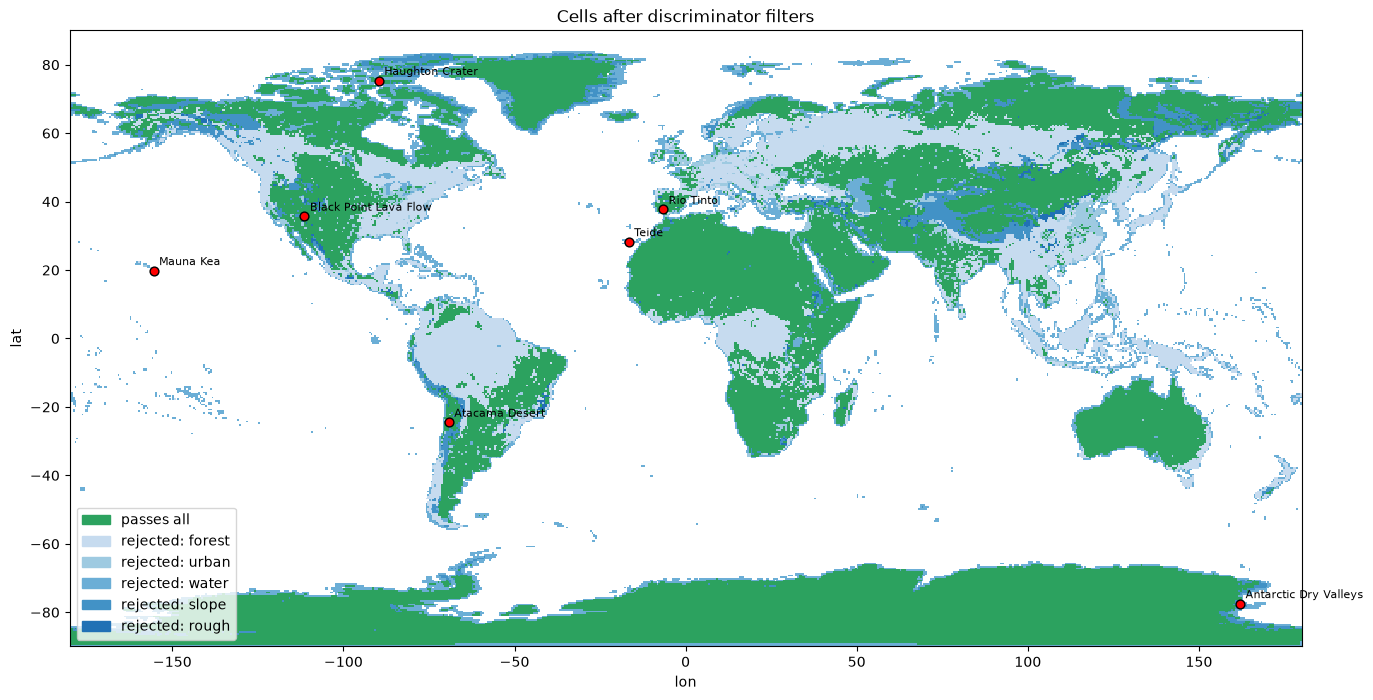

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

NROWS = int(180 / RES)                       # 360

def to_grid(df, values):
    """Put a per-cell value back onto the 360 x 720 grid using cell_id."""
    grid = np.full((NROWS, NCOLS), np.nan)
    rows, cols = np.divmod(df.cell_id.values, NCOLS)
    grid[rows, cols] = values
    return grid

# Category per cell: 0 = passes, 1.. = first filter that rejected it
names = list(FILTERS)
def first_fail(r):
    for i, n in enumerate(names, start=1):
        if not r[f"pass_{n}"]:
            return i
    return 0
cat = cells.apply(first_fail, axis=1).values
grid = to_grid(cells, cat)

colors = ["#2ca25f"] + ["#c6dbef", "#9ecae1", "#6baed6", "#4292c6", "#2171b5"][:len(names)]
fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(grid, extent=[-180, 180, -90, 90], cmap=ListedColormap(colors),
          vmin=0, vmax=len(names), interpolation="nearest")
ax.scatter(analogs.lon, analogs.lat, c="red", s=40, edgecolor="k", zorder=3)
for _, a in analogs.iterrows():
    ax.annotate(a["name"], (a.lon, a.lat), xytext=(4, 4), textcoords="offset points", fontsize=8)

legend = [Patch(color=colors[0], label="passes all")] + \
         [Patch(color=colors[i], label=f"rejected: {n}") for i, n in enumerate(names, start=1)]
ax.legend(handles=legend, loc="lower left")
ax.set_title("Cells after discriminator filters")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.show()

In [23]:
for _, a in analogs.iterrows():
    cid = cell_id(a.lat, a.lon)
    row = cells[cells.cell_id == cid]
    print(f"{a['name']:<25} slope_p90={row.slope_p90.iloc[0]:>6.1f}  "
          f"rough_p10={row.rough_p10.iloc[0]:>6.1f}  "
          f"pass_slope={row.pass_slope.iloc[0]}  pass_rough={row.pass_rough.iloc[0]}")

Atacama Desert            slope_p90=   9.1  rough_p10=   8.9  pass_slope=True  pass_rough=True
Antarctic Dry Valleys     slope_p90=  26.6  rough_p10=   7.1  pass_slope=False  pass_rough=True
Haughton Crater           slope_p90=   4.1  rough_p10=   3.6  pass_slope=True  pass_rough=True
Mauna Kea                 slope_p90=   8.1  rough_p10=   9.4  pass_slope=True  pass_rough=True
Black Point Lava Flow     slope_p90=   3.0  rough_p10=   2.7  pass_slope=True  pass_rough=True
Rio Tinto                 slope_p90=   6.3  rough_p10=  10.1  pass_slope=True  pass_rough=True
Teide                     slope_p90=  16.4  rough_p10=  19.1  pass_slope=False  pass_rough=False
